# PA2 · Question 2 · Step 3: build model A (the ConvLSTM)

**Today's goal (about 60–90 minutes).** Build model A exactly as the handout describes, and check it. **No training yet**: training is Step 4, on a GPU.

You write **three parts** (✏️ YOUR TURN), and each has an automatic check:

1. **`ConvLSTMCell.forward`**: the gate equations (handout Eqs. 3–4).
2. **`ModelA.step`**: one time step: fold the frame → layer 1 → layer 2 → output head → unfold.
3. **`ModelA.forward`**: the 9-step rollout, where the model feeds its own predictions back in.

**Kaggle settings:** Internet **On**, Accelerator **None** (no GPU needed for this step).

In [1]:
import os, glob
import numpy as np
import torch, torchvision
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
print("torch", torch.__version__)

torch 2.11.0+cu128


## 0. Data and your Step 1 functions

The first cell loads the data, the same code as before. The second contains **your own Step 1 functions**, already checked in Table 1.

In [2]:
ON_KAGGLE = os.path.exists("/kaggle/input")
DATA_ROOT = "/tmp/mmnist" if ON_KAGGLE else "./data"
found = glob.glob("/kaggle/input/**/mnist_test_seq.npy", recursive=True) if ON_KAGGLE else []
if found:
    os.makedirs(os.path.join(DATA_ROOT, "MovingMNIST"), exist_ok=True)
    link = os.path.join(DATA_ROOT, "MovingMNIST", "mnist_test_seq.npy")
    if not os.path.exists(link):
        os.symlink(found[0], link)
ds = torchvision.datasets.MovingMNIST(root=DATA_ROOT, split=None, download=True)
videos_u8 = ds.data if hasattr(ds, "data") else torch.stack([ds[i] for i in range(len(ds))])
assert tuple(videos_u8.shape) == (10000, 20, 1, 64, 64)
train_u8, val_u8, test_u8 = videos_u8[:8000], videos_u8[8000:9000], videos_u8[9000:]
def to_float(v_u8):
    return v_u8.float() / 255.0
print("data ready")

100%|██████████| 819M/819M [00:20<00:00, 40.5MB/s]


data ready


In [3]:
# ---- your Step 1 functions (checked in Table 1) ----
def mirror(x):
    return torch.flip(x, dims=[-1])

def rotate(x, a=1):
    return torch.rot90(x, k=a, dims=(-2, -1))

def make_window(video, t, k=1):
    in_nums  = [t + j*k for j in range(5)]
    out_nums = [t + j*k for j in range(5, 10)]
    X = video[[n - 1 for n in in_nums]]
    mask = torch.tensor([n <= 20 for n in out_nums])
    Y = torch.zeros(5, *video.shape[1:], dtype=video.dtype)
    for j, n in enumerate(out_nums):
        if n <= 20:
            Y[j] = video[n - 1]
    return X, Y, mask

def apply_g(x, a, m):
    y = rotate(x, a)
    return mirror(y) if m else y

def apply_g_inverse(x, a, m):
    y = mirror(x) if m else x
    return rotate(y, -a)

## 1. Background: what a ConvLSTM is

### 1.1 From LSTM to ConvLSTM

An **LSTM** is a recurrent network: it reads a sequence one step at a time and carries a **memory** forward. At each step it keeps two things:

* **c**, the *cell state*: the long-term memory;
* **h**, the *hidden state*: what the layer shows to the next layer and to the next time step.

At every step, it makes four decisions with four **gates**:

| Gate | Name | Squashed with | Range | Its job |
|---|---|---|---|---|
| **i** | input gate | sigmoid σ | 0 … 1 | *how much* new content to write into memory |
| **f** | forget gate | sigmoid σ | 0 … 1 | *how much* old memory to keep |
| **o** | output gate | sigmoid σ | 0 … 1 | *how much* of the memory to show as h |
| **g** | candidate | tanh | −1 … 1 | the new content itself |

A gate value of 0 means "closed" (nothing passes) and 1 means "fully open".

In a normal LSTM, h and c are **vectors** and the gates come from matrix multiplications. In a **ConvLSTM** (Shi et al., 2015), h and c are **images**: grids with many channels. The matrix multiplication is replaced by a **3×3 convolution**. So:

* each grid position only looks at its **3×3 neighbourhood**, which suits moving objects, because motion is local;
* the **same rule** is used at every position (weight sharing), so a digit moving in the top-left corner is handled like one in the bottom-right.

### 1.2 The handout's equations (Eqs. 3–4)

$$[\,i,\ f,\ o,\ g\,] = \mathrm{Conv}_{3\times3}\big([\,u_\tau,\ h_{\tau-1}\,]\big)$$

$$c_\tau = \sigma(f)\odot c_{\tau-1} + \sigma(i)\odot\tanh(g), \qquad h_\tau = \sigma(o)\odot\tanh(c_\tau)$$

* $[u_\tau,\ h_{\tau-1}]$ means **channel concatenation**: stack the new input and the previous hidden state along the channel axis. The order is **u first, then h**.
* **One** convolution produces all four gates at once: it outputs $4 \times 64 = 256$ channels, which are then split into 4 groups of 64, **in the order i, f, o, g**.
* $\odot$ means element-by-element multiplication (in PyTorch, just `*`).
* **In words, for c:** new memory = (keep part of old memory) + (write part of new content).
* **In words, for h:** output = (open part of the) squashed memory.
* There are **no peephole terms**: c is never fed into the gate convolution.

### 1.3 Why fold 4×4 patches into channels (`pixel_unshuffle`)

`F.pixel_unshuffle(x, 4)` cuts the 64×64 frame into 4×4 patches and stacks each patch's 16 pixels as **16 channels**. So 1×64×64 becomes **16×16×16**. No information is lost: `pixel_shuffle` puts every pixel back exactly.

**Why do it?**

* There are 16× fewer grid positions (256 instead of 4,096), so every convolution is much cheaper.
* One grid cell now stands for **4 original pixels** in each direction. Remember this for the reach question (Q2.3).

The next cell shows a tiny example with a 4×4 image and patch size 2.

In [4]:
tiny = torch.arange(1, 17).float().view(1, 1, 4, 4)     # (batch, channel, 4, 4)
print("original 4x4 image:\n", tiny[0, 0])
folded = F.pixel_unshuffle(tiny, 2)                        # -> (1, 4, 2, 2)
print("\nafter pixel_unshuffle(., 2): shape", tuple(folded.shape))
for ch in range(4):
    print(f"channel {ch}:\n", folded[0, ch])
print("\npixel_shuffle undoes it exactly:", torch.equal(F.pixel_shuffle(folded, 2), tiny))

original 4x4 image:
 tensor([[ 1.,  2.,  3.,  4.],
        [ 5.,  6.,  7.,  8.],
        [ 9., 10., 11., 12.],
        [13., 14., 15., 16.]])

after pixel_unshuffle(., 2): shape (1, 4, 2, 2)
channel 0:
 tensor([[ 1.,  3.],
        [ 9., 11.]])
channel 1:
 tensor([[ 2.,  4.],
        [10., 12.]])
channel 2:
 tensor([[ 5.,  7.],
        [13., 15.]])
channel 3:
 tensor([[ 6.,  8.],
        [14., 16.]])

pixel_shuffle undoes it exactly: True


Each 2×2 patch (for example the top-left `1 2 / 5 6`) becomes **one position with 4 channels**: its values 1, 2, 5, 6 now sit at position (0, 0) of channels 0, 1, 2, 3. In model A the patch is 4×4, so every position carries 16 channels.

### 1.4 Model A, one time step

```
frame u  (1×64×64)
   │  pixel_unshuffle(4)              fold 4×4 patches into channels
   ▼
16×16×16
   │  ConvLSTM layer 1 (64 ch)    ◄── its own memory (h1, c1) from the previous step
   ▼
h1  (64×16×16)
   │  ConvLSTM layer 2 (64 ch)    ◄── its own memory (h2, c2) from the previous step
   ▼
h2  (64×16×16)
   │  1×1 conv, 64 → 16 channels
   ▼
16×16×16
   │  pixel_shuffle(4), then sigmoid  unfold back to pixels; squash into [0, 1]
   ▼
prediction of the NEXT frame  (1×64×64)
```

Layer 2 takes layer 1's **new** hidden state from **this** step. All memories start at **zero** for every video.

### 1.5 The 9-step rollout (no teacher forcing)

At step τ the model takes one frame $u_\tau$ and predicts the **next** frame $\hat x_{\tau+1}$.

| Handout step τ | Python index | Input $u_\tau$ | Output | Kept in Ŷ? |
|---|---|---|---|---|
| 1 | 0 | $x_1$ (true) | $\hat x_2$ | no |
| 2 | 1 | $x_2$ (true) | $\hat x_3$ | no |
| 3 | 2 | $x_3$ (true) | $\hat x_4$ | no |
| 4 | 3 | $x_4$ (true) | $\hat x_5$ | no |
| **5** | **4** | $x_5$ (true) | $\hat x_6$ | **yes: 1st forecast** |
| 6 | 5 | $\hat x_6$ (**its own** prediction) | $\hat x_7$ | yes |
| 7 | 6 | $\hat x_7$ (own) | $\hat x_8$ | yes |
| 8 | 7 | $\hat x_8$ (own) | $\hat x_9$ | yes |
| 9 | 8 | $\hat x_9$ (own) | $\hat x_{10}$ | yes |

* **No teacher forcing:** true future frames are **never** fed in. At test time the true future is unknown, so the model is trained the same way it will be used.
* **Do not `.detach()` the fed-back predictions.** Gradients must flow through them, so the model learns that its own errors are carried forward.
* The same weights are used at every step: the same `cell1`, `cell2` and `head`.

### 1.6 Parameter count (the handout's check: 480,784)

One ConvLSTM layer has one convolution from $(C_{in} + C_h)$ channels to $4C_h$ channels, with a $k\times k$ kernel and $4C_h$ biases:

$$P_{\text{layer}} = (C_{in}+C_h)\cdot 4C_h\cdot k^2 + 4C_h$$

| Part | Calculation | Parameters |
|---|---|---|
| layer 1 | $(16+64)\cdot256\cdot9 + 256$ | 184,576 |
| layer 2 | $(64+64)\cdot256\cdot9 + 256$ | 295,168 |
| 1×1 head | $64\cdot16 + 16$ | 1,040 |
| **total** | | **480,784** |

## 2. ✏️ YOUR TURN (1): the ConvLSTM cell

`__init__` is written for you: it creates **one** convolution, `self.conv`, from `in_ch + hid_ch` channels to `4 * hid_ch` channels.
You write `forward`, which is the equations of section 1.2.

**Skeleton** (fill the blanks, then delete the `raise` line):

```python
z = self.conv(torch.cat([ ___ , ___ ], dim=1))     # concatenate along channels: u first, then h
i, f, o, g = torch.chunk(z, 4, dim=1)              # split 4*hid channels into 4 gates, in this order
c = torch.sigmoid( ___ ) * c_prev + torch.sigmoid( ___ ) * torch.tanh( ___ )
h = torch.sigmoid( ___ ) * torch.tanh( ___ )
return h, c
```

In [5]:
class ConvLSTMCell(nn.Module):
    def __init__(self, in_ch, hid_ch, k=3):
        super().__init__()
        self.hid_ch = hid_ch
        # ONE convolution makes all 4 gates: (in_ch + hid_ch) channels in  ->  4*hid_ch channels out
        self.conv = nn.Conv2d(in_ch + hid_ch, 4 * hid_ch, kernel_size=k, padding=k // 2, bias=True)

    def forward(self, u, h_prev, c_prev): 
        z = self.conv(torch.cat([ u ,h_prev  ], dim=1)) # u first, then h
        i, f, o, g = torch.chunk(z, 4, dim=1) # 4 gates, in this order 
        c = torch.sigmoid(f) * c_prev + torch.sigmoid(i) * torch.tanh(g) 
        h = torch.sigmoid(o) * torch.tanh(c) 
        return h, c

In [6]:
# ---------- automatic check for the cell (do not edit) ----------
def _det_fill(t, scale, offset=0.0):
    # deterministic "random-looking" numbers, identical on every computer
    n = torch.arange(t.numel(), dtype=torch.float64)
    v = torch.frac(torch.abs(torch.sin(n * 12.9898 + offset * 78.233) * 43758.5453)) * 2 - 1
    return (v * scale).view(t.shape).to(t.dtype)

def _probes(t, k=40):
    flat = t.detach().double().flatten()
    return flat[[(j * 2654435761) % flat.numel() for j in range(k)]]

_REF_C = torch.tensor([0.0776954, 0.94026053, -0.13429902, 0.71796358, 0.29144037, 0.47918761, 0.21204935, 0.18754873, 0.12309532, 0.05022975, -0.44000444, 0.40714335, 0.13839936, -0.12243347, -0.20111613, -0.17252149, 0.40866071, 0.11468054, -0.38033882, -0.02207308, -0.13682066, -0.00292152, 0.11523184, -0.0206062, -0.32123435, 0.36445168, 0.46746975, 0.05471306, -0.12418261, 0.30801582, 0.25461295, -0.31718627, -0.10566913, -0.27096906, -0.01046577, 0.10637775, -0.15316918, 0.31568402, -0.00022478, 0.62073612], dtype=torch.float64)
_REF_H = torch.tensor([0.04392727, 0.28248295, -0.07235567, 0.43994227, 0.15567905, 0.21371144, 0.13942869, 0.13339184, 0.08336293, 0.03133707, -0.18112996, 0.23191302, 0.07652923, -0.03630113, -0.13067402, -0.07439484, 0.19802693, 0.05372835, -0.17957443, -0.01083636, -0.08868653, -0.00149059, 0.05073823, -0.00695133, -0.04676762, 0.24454534, 0.23037076, 0.0331325, -0.06881874, 0.13209561, 0.10821167, -0.22967744, -0.05981715, -0.1550733, -0.00423965, 0.04732657, -0.0941491, 0.20836365, -8.954e-05, 0.26831052], dtype=torch.float64)

def check_cell():
    cell = ConvLSTMCell(16, 64)
    with torch.no_grad():
        cell.conv.weight.copy_(_det_fill(cell.conv.weight, 0.1, 1.0))
        cell.conv.bias.copy_(_det_fill(cell.conv.bias, 0.2, 2.0))
        u  = _det_fill(torch.empty(2, 16, 16, 16), 1.0, 3.0)
        h0 = _det_fill(torch.empty(2, 64, 16, 16), 0.5, 4.0)
        c0 = _det_fill(torch.empty(2, 64, 16, 16), 0.8, 5.0)
        out = cell(u, h0, c0)
    if not (isinstance(out, (tuple, list)) and len(out) == 2):
        return print("FIX: forward must return two things: h, c")
    h, c = out
    if tuple(h.shape) != (2, 64, 16, 16) or tuple(c.shape) != (2, 64, 16, 16):
        return print(f"FIX: h and c must both have shape (2, 64, 16, 16); got {tuple(h.shape)} and {tuple(c.shape)}")
    c_ok = (_probes(c) - _REF_C).abs().max().item() < 1e-4
    h_ok = (_probes(h) - _REF_H).abs().max().item() < 1e-4
    if c_ok and h_ok:
        print("OK: ConvLSTMCell is correct (shapes and values match the handout's equations).")
    elif not c_ok:
        print("FIX: c is wrong. Check: (1) concatenation order [u, h_prev]; (2) gate order i, f, o, g in torch.chunk;"
              " (3) the c line: sigmoid(f) * c_prev + sigmoid(i) * tanh(g).")
    else:
        print("FIX: c is correct but h is wrong. Check the h line: sigmoid(o) * tanh(c), using the NEW c.")

try:
    check_cell()
except NotImplementedError:
    print("ConvLSTMCell.forward not written yet.")

OK: ConvLSTMCell is correct (shapes and values match the handout's equations).


## 3. ✏️ YOUR TURN (2): one time step of model A

`__init__` and `init_states` are written for you. You write `step`, which is the diagram in section 1.4.

**Skeleton:**

```python
h1, c1, h2, c2 = states
x = F.pixel_unshuffle(u, self.patch)            # (B, 1, 64, 64) -> (B, 16, 16, 16)
h1, c1 = self.cell1( ___ , h1, c1)              # layer 1 takes the folded frame
h2, c2 = self.cell2( ___ , h2, c2)              # layer 2 takes layer 1's NEW hidden state
y = self.head( ___ )                            # 64 -> 16 channels
pred = torch.sigmoid(F.pixel_shuffle(y, self.patch))   # -> (B, 1, 64, 64), values in (0, 1)
return pred, [h1, c1, h2, c2]                   # also return the UPDATED memories
```

## 4. ✏️ YOUR TURN (3): the 9-step rollout

You write `forward` (in the same class, below `step`). It follows the table in section 1.5.

**Skeleton:**

```python
B, _, _, H, W = X.shape
states = self.init_states(B, H // self.patch, W // self.patch, X.device)   # all zeros
outputs = []
pred = None
for tau in range(9):                     # Python 0..8  <->  handout steps 1..9
    u = X[:, tau] if tau < 5 else ___    # steps 1-5: true input frames; steps 6-9: own previous prediction
    pred, states = self.step(u, states)
    outputs.append(pred)
return torch.stack(outputs[ ___ : ], dim=1)   # keep the outputs of handout steps 5..9  ->  (B, 5, 1, 64, 64)
```

Think about the last blank carefully: which **Python index** is handout step 5?

In [7]:
class ModelA(nn.Module):
    def __init__(self, hid=64, patch=4):
        super().__init__()
        self.patch, self.hid = patch, hid
        C = patch * patch                                    # 16 channels after folding 4x4 patches
        self.cell1 = ConvLSTMCell(C, hid)                    # layer 1: 16 -> 64
        self.cell2 = ConvLSTMCell(hid, hid)                  # layer 2: 64 -> 64
        self.head  = nn.Conv2d(hid, C, kernel_size=1, bias=True)   # 1x1 conv: 64 -> 16

    def init_states(self, B, H, W, device):
        # h1, c1, h2, c2 all start at zero for every video
        return [torch.zeros(B, self.hid, H, W, device=device) for _ in range(4)]

    def step(self, u, states):
        h1, c1, h2, c2 = states
        x = F.pixel_unshuffle(u, self.patch) # (B,1,64,64) -> (B,16,16,16)
        h1, c1 = self.cell1(x , h1, c1) # layer 1 takes the folded frame
        h2, c2 = self.cell2( h1 , h2, c2) # layer 2 takes layer 1's NEW h1
        y = self.head( h2) # 64 -> 16 channels
        pred = torch.sigmoid(F.pixel_shuffle(y, self.patch)) # back to (B,1,64,64)
        return pred, [h1, c1, h2, c2] # the UPDATED memories

    def forward(self, X):
        B, _, _, H, W = X.shape
        states = self.init_states(B, H // self.patch, W // self.patch, X.device)
        outputs = []
        pred = None
        for tau in range(9):
            u = X[:, tau] if tau < 5 else pred # true frame for steps 1-5, own prediction for 6-9
            pred, states = self.step(u, states)
            outputs.append(pred)
        return torch.stack(outputs[ 4 : ], dim=1)

In [8]:
# ---------- automatic check for step (do not edit) ----------
_REF_STEP = torch.tensor([0.47322363, 0.48425829, 0.504637, 0.51833487, 0.46874601, 0.55317032, 0.47046751, 0.45602658, 0.4522146, 0.4495438, 0.47241059, 0.52240306, 0.53283513, 0.48067102, 0.4960508, 0.50776118, 0.47582769, 0.4835858, 0.50522, 0.51424468, 0.4653964, 0.48377219, 0.47228706, 0.46025917, 0.45048475, 0.54756647, 0.47342563, 0.5202207, 0.53565419, 0.44786012, 0.49892762, 0.51200968, 0.47343567, 0.48397225, 0.4979983, 0.51611644, 0.46439785, 0.48742372, 0.50307536, 0.45870158, 0.47651607, 0.48247224, 0.50222522, 0.51354408, 0.46908712, 0.55397791, 0.47164392, 0.45573884, 0.45380503, 0.44911444, 0.47506362, 0.52686071, 0.53583694, 0.47797412, 0.49534032, 0.50031042, 0.47697532, 0.48247176, 0.50406033, 0.51181281, 0.46482271, 0.47962925, 0.47295532, 0.45935196, 0.45114926, 0.54514492, 0.4749791, 0.52395982, 0.53746009, 0.44476333, 0.49763834, 0.50468588, 0.47397026, 0.48426473, 0.49797726, 0.51469189, 0.46460074, 0.48501477, 0.5018369, 0.45760509, -0.05102769, 0.11018299, 0.1269055, -0.01952964, 0.12528086, -0.06744108, 0.21819775, 0.06474639, 0.00916488, 0.00580824, -0.04831124, -0.00382711, -0.12557805, -0.07756566, 0.00804358, 0.06733468, -0.08015598, 0.0393588, 0.1071037, 0.01385076, -0.10798712, -0.02558141, 0.01213498, 0.07215669, 0.01535381, -0.08567125, -0.02985867, -0.12404277, 0.03937075, 0.04047174, -0.11175117, 0.08012559, -0.13084446, -0.05610356, -0.07635351, 0.03616567, -0.07214694, -0.15106198, 0.09522193, 0.05594241], dtype=torch.float64)

def check_step():
    m = ModelA()
    n_params = sum(p.numel() for p in m.parameters() if p.requires_grad)
    print(f"trainable parameters: {n_params:,}   (handout: 480,784)  {'OK' if n_params == 480784 else 'FIX'}")
    with torch.no_grad():
        for k, (name, p) in enumerate(m.named_parameters()):
            p.copy_(_det_fill(p, 0.1 if p.dim() > 1 else 0.2, 6.0 + k))
        u = _det_fill(torch.empty(2, 1, 64, 64), 0.5, 9.0) + 0.5
        st = m.init_states(2, 16, 16, "cpu")
        p1, st = m.step(u, st)
        if tuple(p1.shape) != (2, 1, 64, 64):
            return print(f"FIX: pred must have shape (2, 1, 64, 64); got {tuple(p1.shape)}")
        if not (p1.min() > 0 and p1.max() < 1):
            return print("FIX: predictions must lie in (0, 1). Did you apply the sigmoid?")
        if not (isinstance(st, (list, tuple)) and len(st) == 4):
            return print("FIX: step must return the 4 updated states [h1, c1, h2, c2]")
        p2, st = m.step(p1, st)
        got = torch.cat([_probes(p1), _probes(p2), _probes(st[2])])
    if (got - _REF_STEP).abs().max().item() < 1e-4:
        print("OK: step is correct (wiring, output head, unfolding, sigmoid and memory updates all match).")
    else:
        print("FIX: values do not match. (If the ConvLSTMCell check above says FIX, fix the cell first.)"
              " Check: layer 2 must take layer 1's NEW h1; the head must take h2;"
              " pixel_shuffle then sigmoid; and return the UPDATED [h1, c1, h2, c2].")

try:
    check_step()
except NotImplementedError:
    print("step not written yet (or ConvLSTMCell not finished).")

trainable parameters: 480,784   (handout: 480,784)  OK
OK: step is correct (wiring, output head, unfolding, sigmoid and memory updates all match).


In [9]:
# ---------- automatic check for the rollout (do not edit) ----------
def check_rollout():
    torch.manual_seed(0)
    m = ModelA()
    X = torch.rand(2, 5, 1, 64, 64)
    calls = []
    real_step = m.step
    def spy(u, states):                       # records what forward() feeds into each step
        pred, new_states = real_step(u, states)
        calls.append((u, pred))
        return pred, new_states
    m.step = spy
    with torch.enable_grad():
        Y_hat = m(X)
    problems = []
    if len(calls) != 9:
        problems.append(f"step must be called 9 times; it was called {len(calls)} times")
    else:
        for tau in range(5):
            if not torch.equal(calls[tau][0], X[:, tau]):
                problems.append(f"handout step {tau+1} must take the true input frame X[:, {tau}]")
        for tau in range(5, 9):
            u, prev_pred = calls[tau][0], calls[tau - 1][1]
            if not torch.equal(u, prev_pred):
                problems.append(f"handout step {tau+1} must take the model's own previous prediction")
            elif u.grad_fn is None:
                problems.append(f"handout step {tau+1}: the fed-back prediction is detached. Do NOT use .detach(): gradients must flow through it")
        if tuple(Y_hat.shape) != (2, 5, 1, 64, 64):
            problems.append(f"forward must return shape (B, 5, 1, 64, 64); got {tuple(Y_hat.shape)}")
        elif not all(torch.equal(Y_hat[:, j], calls[4 + j][1]) for j in range(5)):
            problems.append("Y_hat must be the outputs of handout steps 5..9 (Python indices 4..8), in order")
    if problems:
        print("FIX:"); [print("  -", p) for p in problems]
    else:
        print("OK: rollout is correct (9 steps, true frames for steps 1-5, own predictions for 6-9, "
              "gradients flow through the feedback, outputs of steps 5-9 returned).")

try:
    check_rollout()
except NotImplementedError:
    print("forward not written yet (or step / ConvLSTMCell not finished).")

OK: rollout is correct (9 steps, true frames for steps 1-5, own predictions for 6-9, gradients flow through the feedback, outputs of steps 5-9 returned).


## 5. Parameter count, part by part (just run)

This should reproduce the table in section 1.6.

In [10]:
torch.manual_seed(0)
model = ModelA()
for name, module in [("layer 1 (cell1)", model.cell1), ("layer 2 (cell2)", model.cell2), ("1x1 head", model.head)]:
    print(f"{name:<16} {sum(p.numel() for p in module.parameters()):>9,}")
print(f"{'total':<16} {sum(p.numel() for p in model.parameters()):>9,}   (handout: 480,784)")

layer 1 (cell1)    184,576
layer 2 (cell2)    295,168
1x1 head             1,040
total              480,784   (handout: 480,784)


## 6. What does an *untrained* model predict? (just run)

The model's weights are still random, so it knows nothing about digits yet. Its outputs sit close to **0.5 (grey)** everywhere: the head's output is close to 0, and $\sigma(0) = 0.5$.
After training in Step 4, the bottom row should start to look like the middle row.

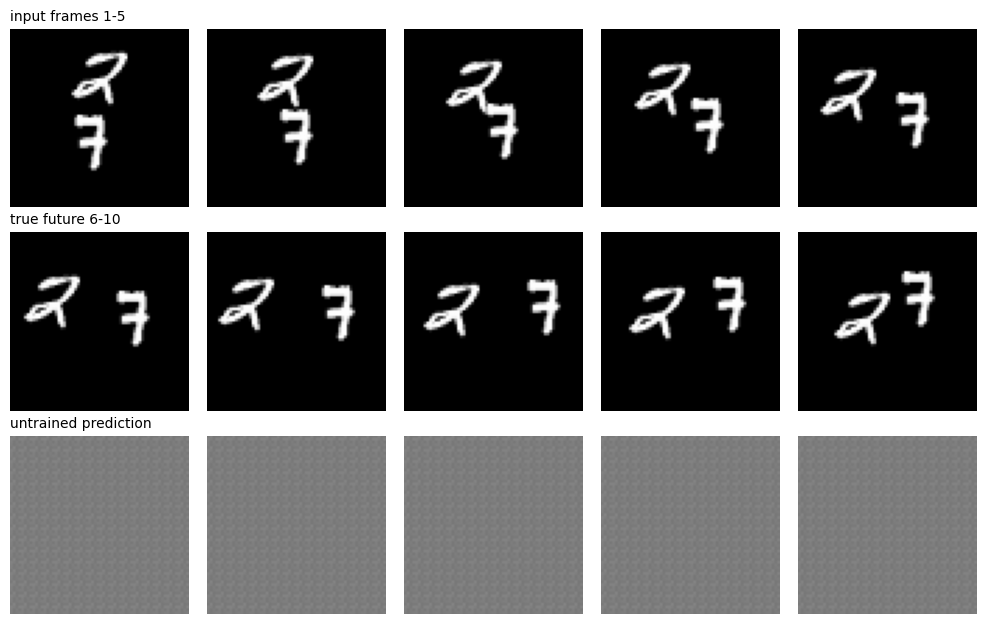

untrained prediction: min 0.467, max 0.518, mean 0.490


In [11]:
video = to_float(train_u8[0])
X, Y, mask = make_window(video, t=1, k=1)
try:
    with torch.no_grad():
        Y_hat = model(X.unsqueeze(0))[0]      # add a batch axis, then remove it
    assert tuple(Y_hat.shape) == (5, 1, 64, 64)
except (NotImplementedError, AssertionError):
    raise SystemExit("Finish the three YOUR TURN parts (all checks OK) before running this cell.")

fig, axes = plt.subplots(3, 5, figsize=(10, 6.3))
rows = [(X, "input frames 1-5"), (Y, "true future 6-10"), (Y_hat, "untrained prediction")]
for r, (frames, label) in enumerate(rows):
    for j in range(5):
        axes[r, j].imshow(frames[j, 0], cmap="gray", vmin=0, vmax=1)
        axes[r, j].axis("off")
    axes[r, 0].set_title(label, loc="left", fontsize=10)
plt.tight_layout(); plt.show()
print(f"untrained prediction: min {Y_hat.min():.3f}, max {Y_hat.max():.3f}, mean {Y_hat.mean():.3f}")

## 7. When all three checks say OK

1. Click **Save Version**. Add today's prompts to `ai_log.md`.
2. **Next, Step 4:** the masked loss, the training loop, and training model A with seeds 0 and 1 on a GPU.
3. **Start thinking about Q2.3 (reach)** while the model is fresh in your mind. Within **one** time step, list every path from $u_\tau$, $h^{(1)}_{\tau-1}$ and $h^{(2)}_{\tau-1}$ to the prediction $\hat x_{\tau+1}$. For each path, count how many **3×3 convolutions** it passes through. Only 3×3 convolutions move information; one grid cell = 4 pixels. Write your answer in your own words.
4. **Remember Q2.5:** your predictions about the mirror, rotation and speed tests must be written and **committed to GitHub before** you run those tests (Step 5).